Abdelrahman Hesham

Task 5 - Part 2: Arabic News (summarizer dataset)

Preprocessing, Visualization, N-grams, POS, NER, Sentiment Analysis, Topic Modeling, ML models with TF-IDF and Transformers

In [1]:
!pip install -q arabic-reshaper python-bidi gensim

In [2]:
import re
import time
import random
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import arabic_reshaper
from bidi.algorithm import get_display
from nltk.corpus import stopwords
import gensim
import gensim.corpora as corpora
from gensim.models import LdaModel, LsiModel, TfidfModel
from gensim.models.coherencemodel import CoherenceModel
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

nltk.download("stopwords", quiet=True)
plt.rcParams["figure.figsize"] = (12, 6)

def ar(text):
    return get_display(arabic_reshaper.reshape(str(text)))

Load the data

In [3]:
data = pd.read_csv("data/summarizdataset.csv")
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8378 entries, 0 to 8377
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   text            8378 non-null   object
 1   type            8378 non-null   object
 2   Processed Text  8378 non-null   object
 3   summarizer      8378 non-null   object
dtypes: object(4)
memory usage: 261.9+ KB


In [4]:
data.head()

,text,type,Processed Text,summarizer
0,\nأشرف رئيس الجمهورية الباجي قايد السبسي اليوم...,culture,اشرف رئيس الجمهوريه الباجي قايد السبسي اليوم ب...,\nأشرف رئيس الجمهورية الباجي قايد السبسي اليوم...
1,"\nتحصل كتاب ""المصحف وقراءاته"" الذي ألفه باحثون...",culture,تحصل كتاب المصحف وقراءاته الفه باحثون تونسيون ...,"\nتحصل كتاب ""المصحف وقراءاته"" الذي ألفه باحثون..."
2,\nاحتضن جناح تونس في القرية الدولية للأفلام بم...,culture,احتضن جناح تونس القريه الدوليه للافلام بمدينه ...,تونس حاضرة من جهة أخرى ستكون تونس حاضرة في قائ...
3,\nشهدت برلين أمس الجمعة افتتاح مسجد فريد من نو...,culture,شهدت برلين الجمعه افتتاح مسجد فريد نوعه الاقل ...,واستأجرت صاحبة المشروع المحامية والكاتبة سيران...
4,\nنعت وزارة الشّؤون الثّقافيّة المنشد الصّوفي ...,culture,نعت وزاره المنشد عز بن محمود انتقل جوار يوم تن...,\nنعت وزارة الشّؤون الثّقافيّة المنشد الصّوفي ...


In [5]:
print(data["text"][0][:400])
print()
print("Summary:", data["summarizer"][0])


أشرف رئيس الجمهورية الباجي قايد السبسي اليوم بقصر قرطاج على موكب منح الوسام الوطني للاستحقاق الثقافي لثلّة من الفنانين والمبدعين و ذلك بمناسبة انعقاد أيام قرطاج السينمائية.
والفنانون هم : *الصنف الأوّل: - عبد الرحمان سيساكو (موريتانيا) - جميل راتب (مصر) - ميشال خليفي (فلسطين) - ادريسا ودراغو (بوركينا فاسو) - محمد ملص (سوريا) - رضا الباهي (تونس: تعذّر عليه الحضور) - عمر الخليفي (تونس) *الصنف الثان

Summary: 
أشرف رئيس الجمهورية الباجي قايد السبسي اليوم بقصر قرطاج على موكب منح الوسام الوطني للاستحقاق الثقافي لثلّة من الفنانين والمبدعين و ذلك بمناسبة انعقاد أيام قرطاج السينمائية.


Preprocessing

- remove diacritics (tashkeel) and tatweel
- normalize letters (أ إ آ to ا, ى to ي, ة to ه)
- remove numbers, English letters and punctuation
- remove Arabic stopwords

In [6]:
def normalize(text):
    text = re.sub(r"[\u064B-\u0652\u0670]", "", text)
    text = re.sub(r"\u0640", "", text)
    text = re.sub(r"[إأآا]", "ا", text)
    text = re.sub(r"ى", "ي", text)
    text = re.sub(r"ة", "ه", text)
    return text

extra_stopwords = ["قال", "وقال", "كان", "كانت", "تم", "وقد", "وفي", "وهو", "وهي", "انه", "اليوم", "امس", "خلال", "حيث", "الي",
                   "علي", "او", "ان", "الذي", "التي", "الذين", "هذا", "هذه", "ذلك", "بعد", "قبل", "كما", "حول", "اطار", "عدد",
                   "مع", "عن", "من", "في", "الى", "على", "ما", "لا", "لم", "لن", "و", "ثم", "اي", "اكثر", "عام", "ايضا", "منذ", "عند"]
ar_stopwords = set(normalize(w) for w in stopwords.words("arabic") + extra_stopwords)

def clean_arabic(text):
    text = normalize(text)
    text = re.sub(r"[^\u0621-\u064A\s]", " ", text)
    tokens = [t for t in text.split() if t not in ar_stopwords and len(t) > 1]
    return tokens

data["tokens"] = data["text"].apply(clean_arabic)
data["text_clean"] = data["tokens"].apply(lambda x: " ".join(x))
data["n_words"] = data["text"].apply(lambda x: len(x.split()))
data["n_words_summary"] = data["summarizer"].apply(lambda x: len(x.split()))
data[["text_clean", "type"]].head()

,text_clean,type
0,اشرف رئيس الجمهوريه الباجي قايد السبسي بقصر قر...,culture
1,تحصل كتاب المصحف وقراءاته الفه باحثون تونسيون ...,culture
2,احتضن جناح تونس القريه الدوليه للافلام بمدينه ...,culture
3,شهدت برلين الجمعه افتتاح مسجد فريد نوعه الاقل ...,culture
4,نعت وزاره الشؤون الثقافيه المنشد الصوفي عز الد...,culture


Visualization

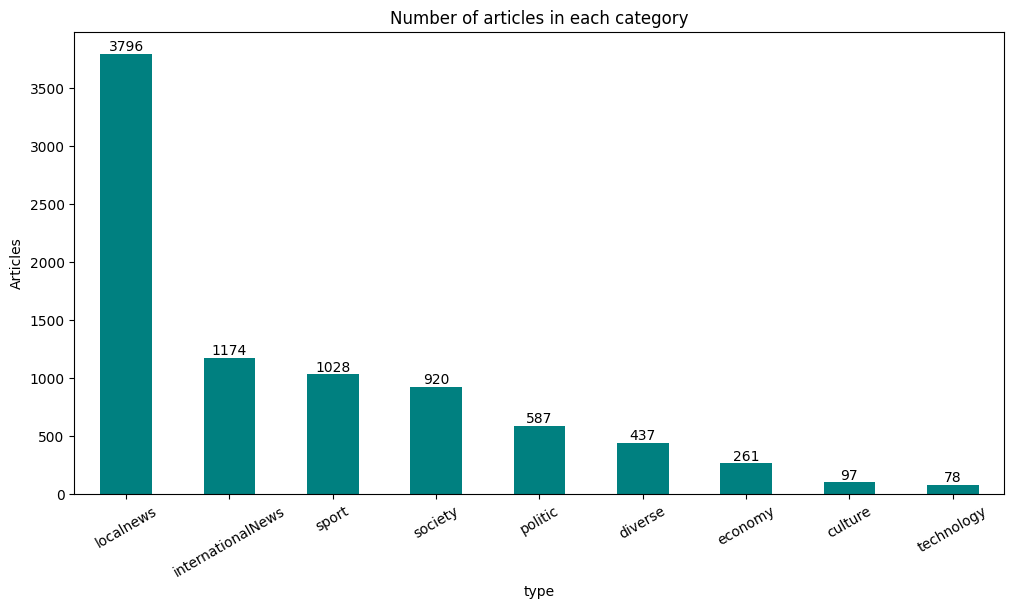

In [7]:
counts = data["type"].value_counts()
ax = counts.plot.bar(color="teal")
for i, v in enumerate(counts):
    ax.text(i, v + 30, str(v), ha="center")
plt.title("Number of articles in each category")
plt.ylabel("Articles")
plt.xticks(rotation=30)
plt.show()

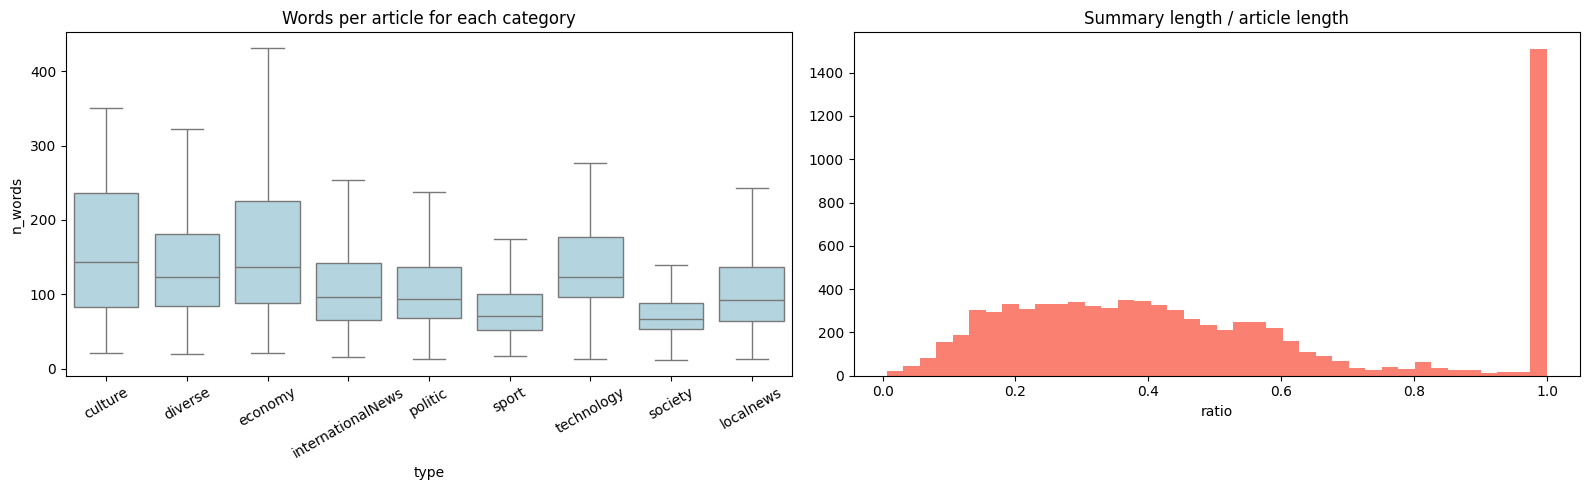

Average article length: 112 words
Average summary length: 42 words


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=data, x="type", y="n_words", showfliers=False, ax=ax[0], color="lightblue")
ax[0].set_title("Words per article for each category")
ax[0].tick_params(axis="x", rotation=30)

ratio = data["n_words_summary"] / data["n_words"]
ax[1].hist(ratio, bins=40, color="salmon")
ax[1].set_title("Summary length / article length")
ax[1].set_xlabel("ratio")
plt.tight_layout()
plt.show()

print("Average article length:", round(data["n_words"].mean()), "words")
print("Average summary length:", round(data["n_words_summary"].mean()), "words")

N-grams: most and least repeated words

Total words: 680953
Unique words: 67757
Words that appear only once: 30044


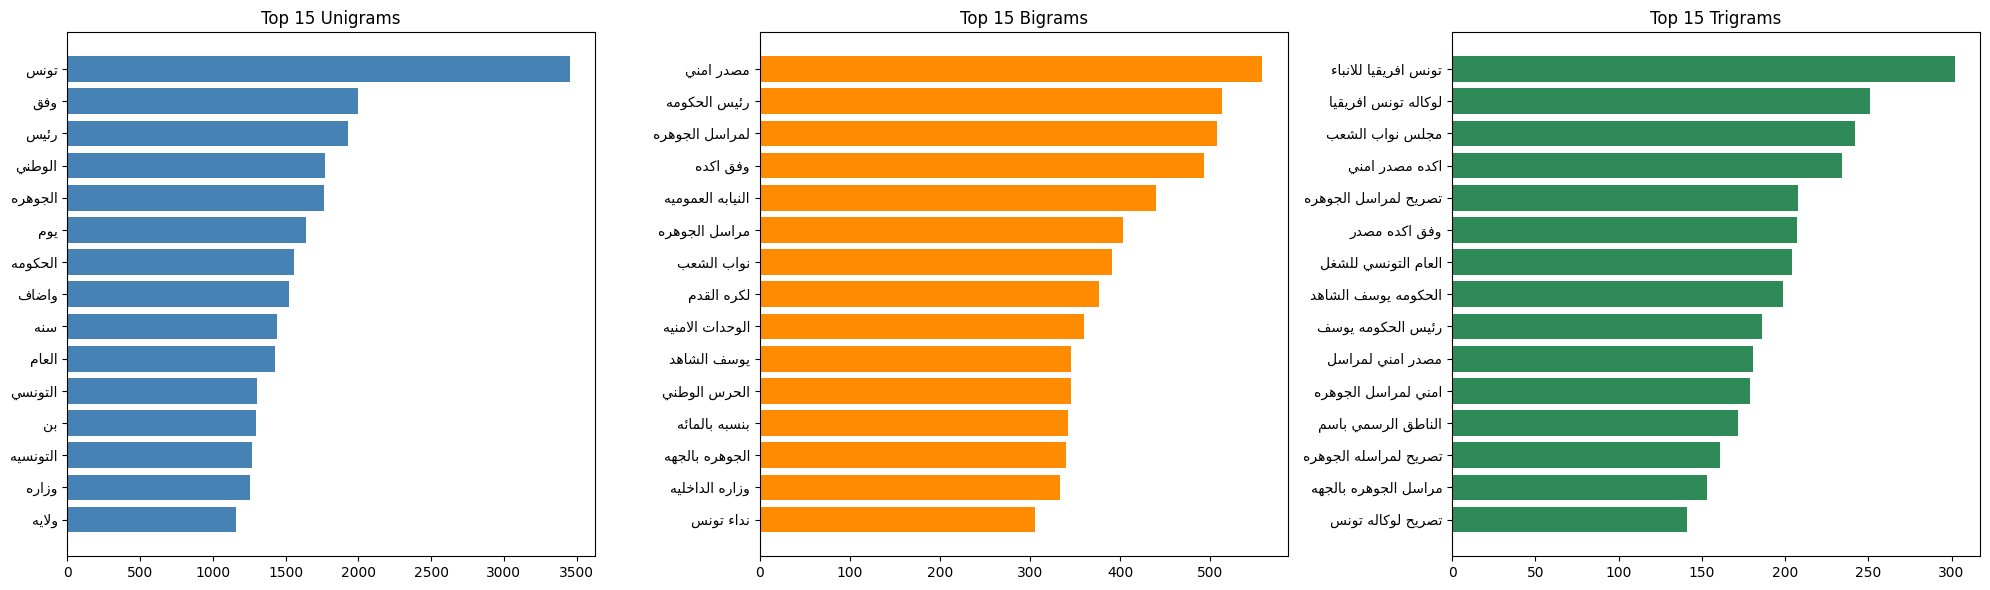

In [9]:
all_tokens = sum(data["tokens"], [])
word_counts = pd.Series(all_tokens).value_counts()
print("Total words:", len(all_tokens))
print("Unique words:", len(word_counts))
print("Words that appear only once:", (word_counts == 1).sum())

def ngram_counts(tokens_list, n, top=15):
    grams = []
    for tokens in tokens_list:
        grams += [" ".join(g) for g in nltk.ngrams(tokens, n)]
    return pd.Series(grams).value_counts()[:top]

unigrams = ngram_counts(data["tokens"], 1)
bigrams = ngram_counts(data["tokens"], 2)
trigrams = ngram_counts(data["tokens"], 3)

fig, ax = plt.subplots(1, 3, figsize=(20, 6))
for i, (s, name, color) in enumerate([(unigrams, "Unigrams", "steelblue"), (bigrams, "Bigrams", "darkorange"), (trigrams, "Trigrams", "seagreen")]):
    s = s[::-1]
    ax[i].barh([ar(x) for x in s.index], s.values, color=color)
    ax[i].set_title("Top 15 " + name)
plt.tight_layout()
plt.show()

In [10]:
print("Some words that appear only once:")
print(list(word_counts[word_counts == 1].index[:30]))

Some words that appear only once:
['قريميط', 'وتوافقا', 'خنقه', 'الزلاق', 'والتوصيات', 'تبلغها', 'صانعي', 'والصفره', 'وتروكديرو', 'ويلوح', 'النقوش', 'فخامه', 'اجتازا', 'تسليمهما', 'يدرج', 'واثمر', 'دستورا', 'الميلاديه', 'لساحه', 'ودشنه', 'بنقش', 'تقزيما', 'تضخيما', 'للمنتمين', 'فوجؤوا', 'بوالد', 'ويشحنها', 'بالخراطيش', 'والامدادات', 'تحسيسي']


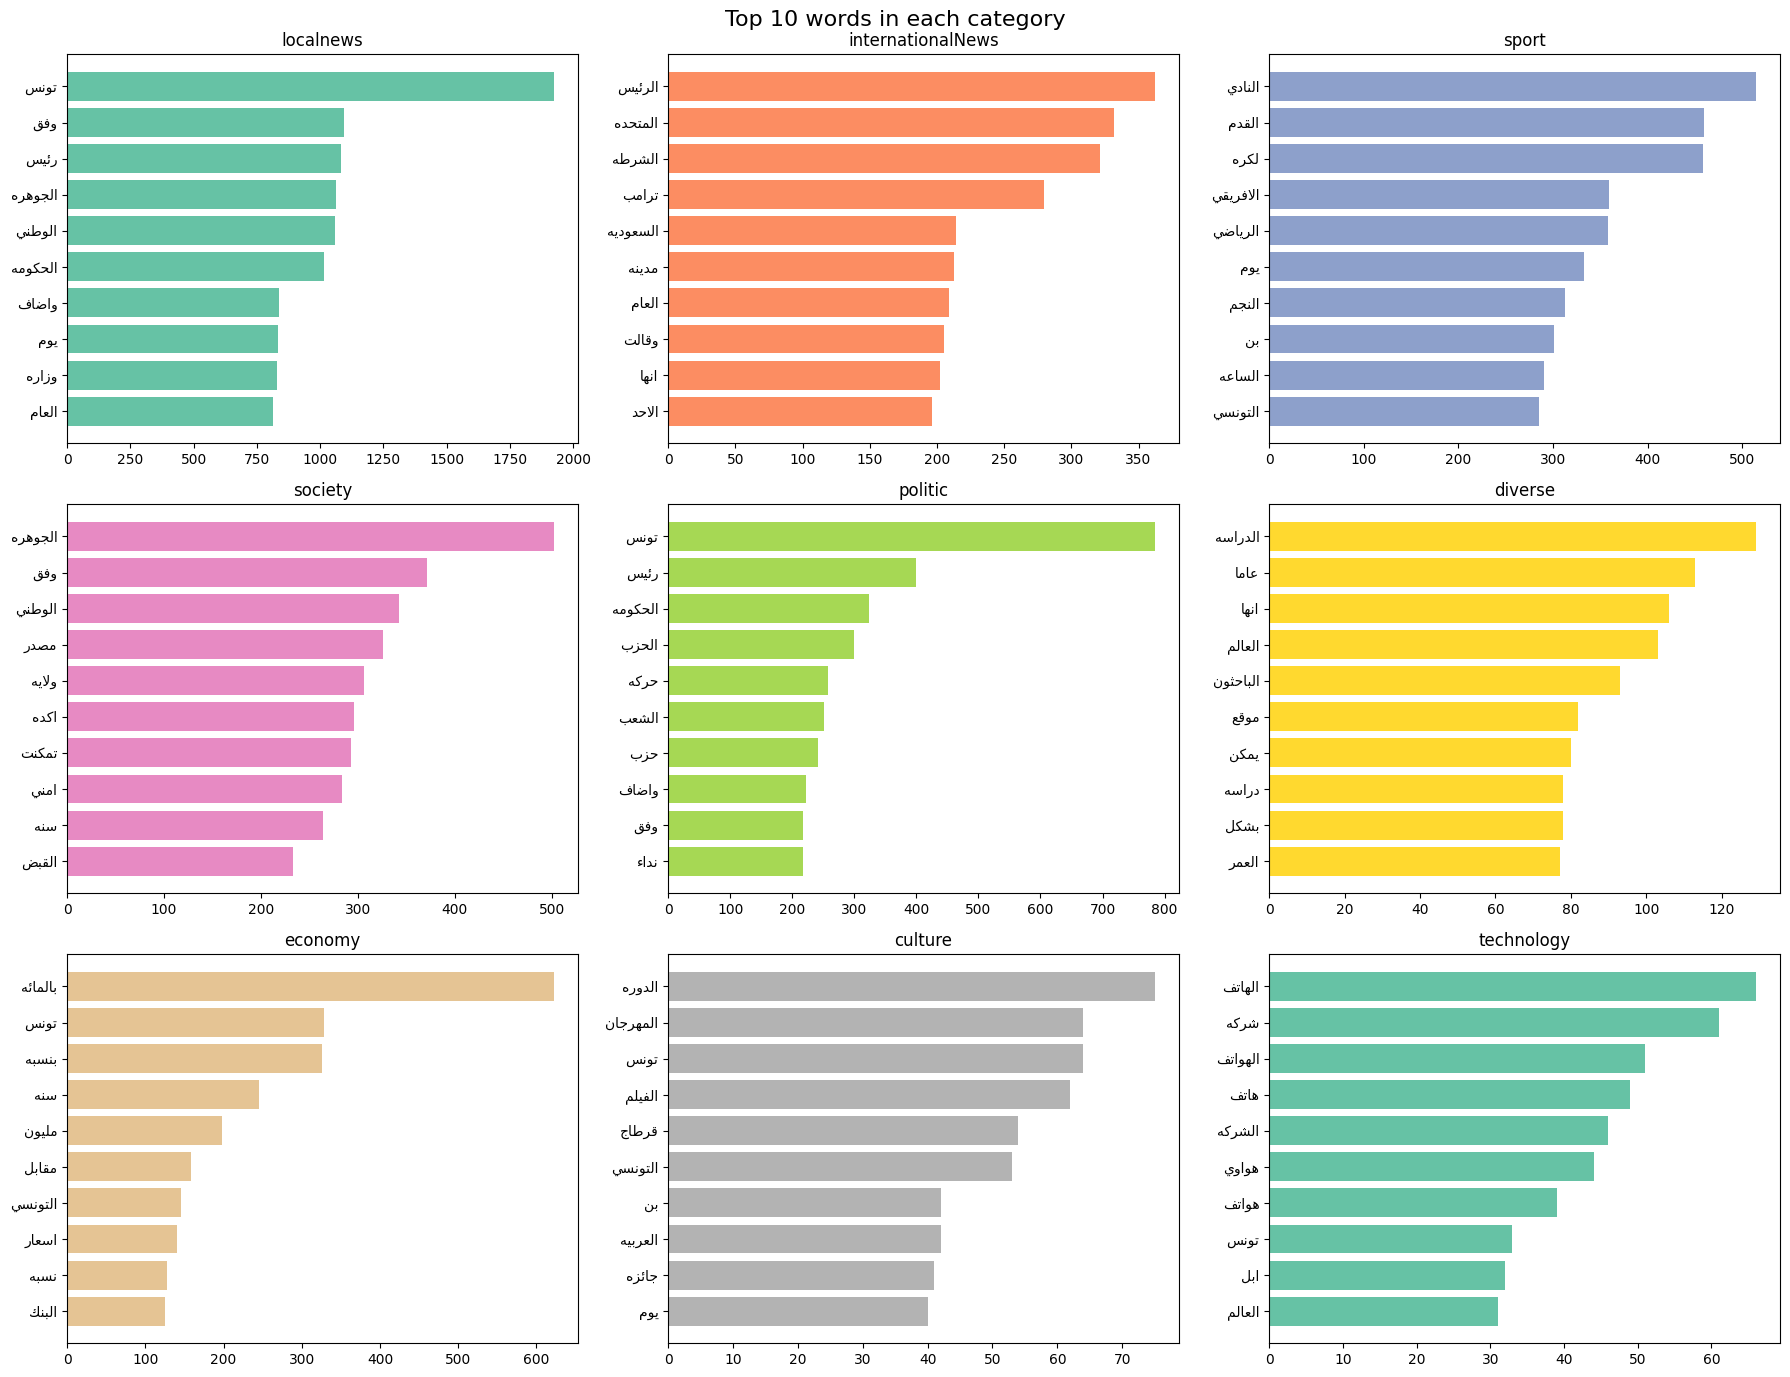

In [11]:
types = data["type"].value_counts().index
fig, ax = plt.subplots(3, 3, figsize=(18, 14))
for i, t in enumerate(types):
    s = pd.Series(sum(data[data["type"] == t]["tokens"], [])).value_counts()[:10][::-1]
    a = ax[i // 3, i % 3]
    a.barh([ar(x) for x in s.index], s.values, color=sns.color_palette("Set2")[i % 8])
    a.set_title(t)
plt.suptitle("Top 10 words in each category", fontsize=16)
plt.tight_layout()
plt.show()

POS Tagging and NER

spaCy does not have an Arabic model, so I used the CAMeLBERT token classification models from Hugging Face. The models are slow, so I used 35 articles from each category (first 120 words of each).

In [12]:
from transformers import pipeline
import torch
device = 0 if torch.cuda.is_available() else -1
print("GPU:", torch.cuda.is_available())

sample = data.groupby("type").head(35).reset_index(drop=True)
sample_texts = sample["text"].apply(lambda x: " ".join(x.split()[:120])).tolist()
print(len(sample_texts))

GPU: True
315


In [13]:
pos_pipe = pipeline("token-classification", model="CAMeL-Lab/bert-base-arabic-camelbert-msa-pos-msa", aggregation_strategy="simple", device=device)

pos_rows = []
for t, res in zip(sample["type"], pos_pipe(sample_texts, batch_size=16)):
    for r in res:
        pos_rows.append({"token": normalize(r["word"]), "pos_tag": r["entity_group"], "type": t})
pos_df = pd.DataFrame(pos_rows)
pos_df = pos_df[~pos_df["pos_tag"].isin(["punc", "digit"])]
pos_df.head(10)

[transformers] BertForTokenClassification LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-msa-pos-msa
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,token,pos_tag,type
0,اشرف,verb,culture
1,رئيس الجمهوريه,noun,culture
2,الباجي قايد السبسي,noun_prop,culture
3,اليوم بقصر,noun,culture
4,قرطاج,noun_prop,culture
5,علي,prep,culture
6,موكب منح الوسام,noun,culture
7,الوطني,adj,culture
8,للاستحقاق,noun,culture
9,الثقافي,adj,culture


pos_tag
noun         7694
prep         3280
adj          3057
verb         2822
noun_prop    1883
conj_sub      539
pron_rel      467
pron_dem      272
conj          272
noun_num      216
abbrev        159
adj_num       157
Name: count, dtype: int64


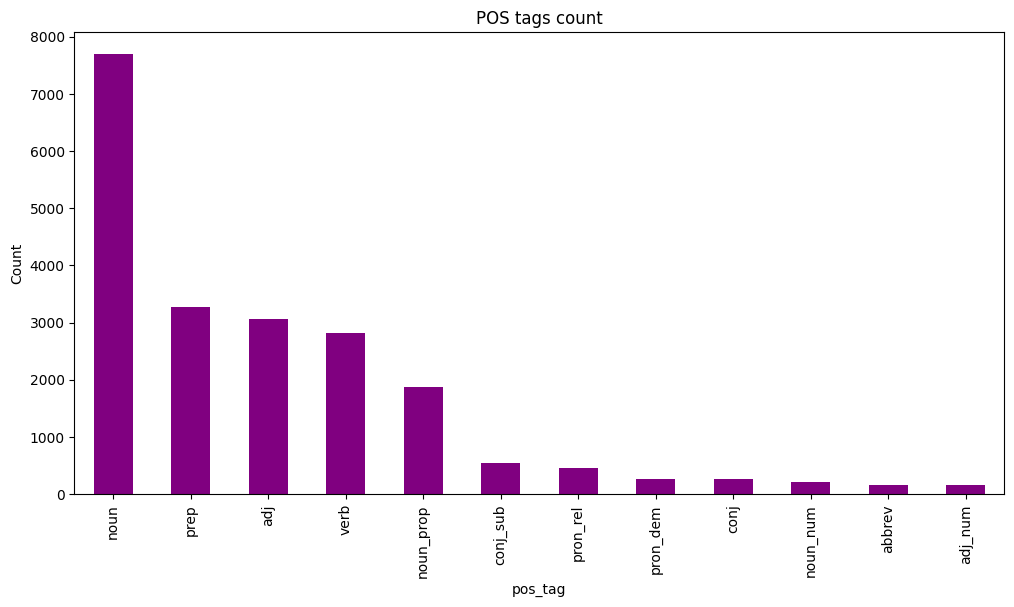

In [14]:
pos_tag_counts = pos_df["pos_tag"].value_counts()
print(pos_tag_counts.head(12))

pos_tag_counts.head(12).plot.bar(color="purple")
plt.title("POS tags count")
plt.ylabel("Count")
plt.show()

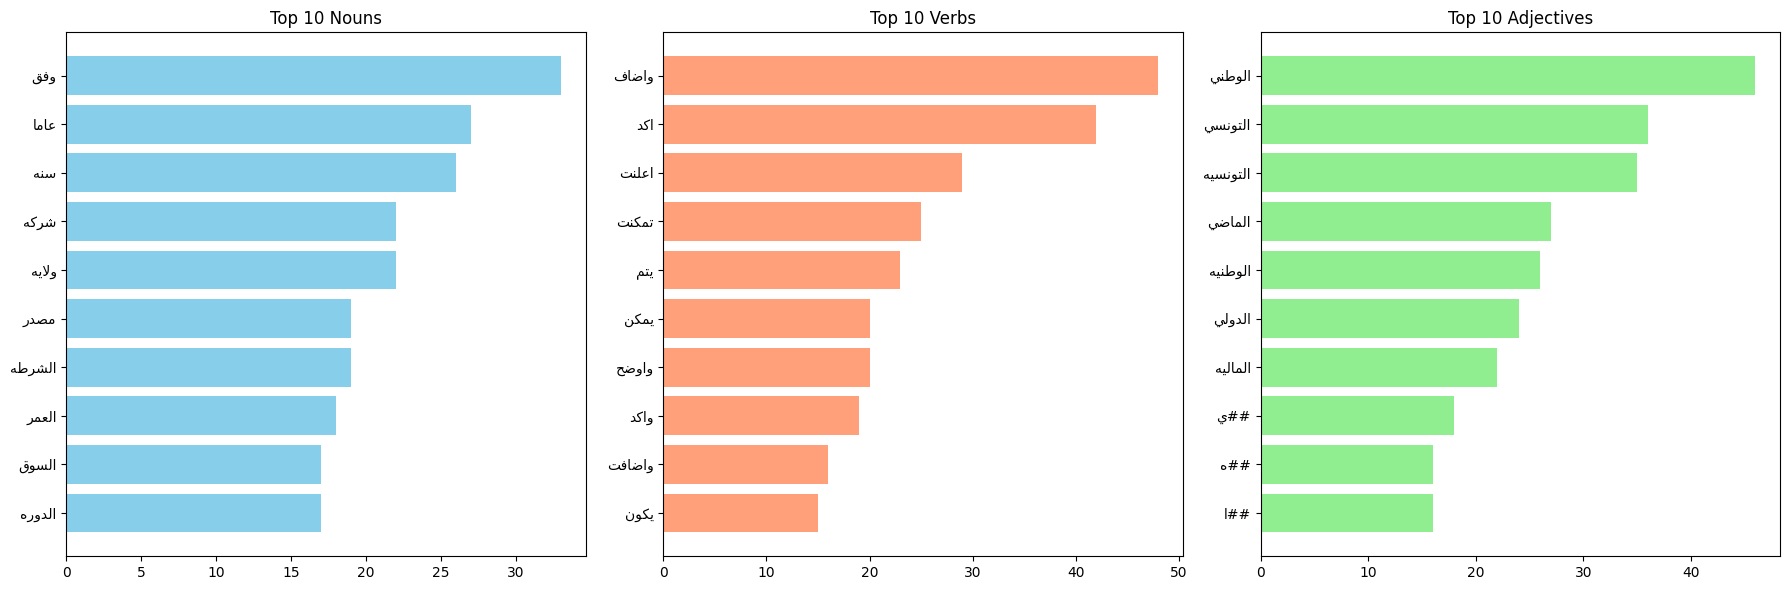

In [15]:
pos_counts = pos_df[~pos_df["token"].isin(ar_stopwords)].groupby(["token", "pos_tag"]).size().reset_index(name="counts").sort_values("counts", ascending=False)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for i, (tag, name, color) in enumerate([("noun", "Nouns", "skyblue"), ("verb", "Verbs", "lightsalmon"), ("adj", "Adjectives", "lightgreen")]):
    s = pos_counts[pos_counts.pos_tag == tag][:10][::-1]
    ax[i].barh([ar(x) for x in s["token"]], s["counts"], color=color)
    ax[i].set_title("Top 10 " + name)
plt.tight_layout()
plt.show()

In [16]:
ner_pipe = pipeline("token-classification", model="CAMeL-Lab/bert-base-arabic-camelbert-msa-ner", aggregation_strategy="simple", device=device)

ner_rows = []
for t, res in zip(sample["type"], ner_pipe(sample_texts, batch_size=16)):
    for r in res:
        ner_rows.append({"token": r["word"], "ner_tag": r["entity_group"], "type": t})
ner_df = pd.DataFrame(ner_rows)
ner_df.head(10)

[transformers] BertForTokenClassification LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-msa-ner
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,token,ner_tag,type
0,البا,PERS,culture
1,##جي قايد السبسي,PERS,culture
2,قرطاج,LOC,culture
3,قرطاج,LOC,culture
4,عبد الرحمان سيساكو,PERS,culture
5,موريتانيا,LOC,culture
6,جميل راتب,PERS,culture
7,مصر,LOC,culture
8,ميشال خليفي,PERS,culture
9,فلسطين,LOC,culture


ner_tag
LOC     1049
ORG      709
PERS     619
MISC     399
Name: count, dtype: int64


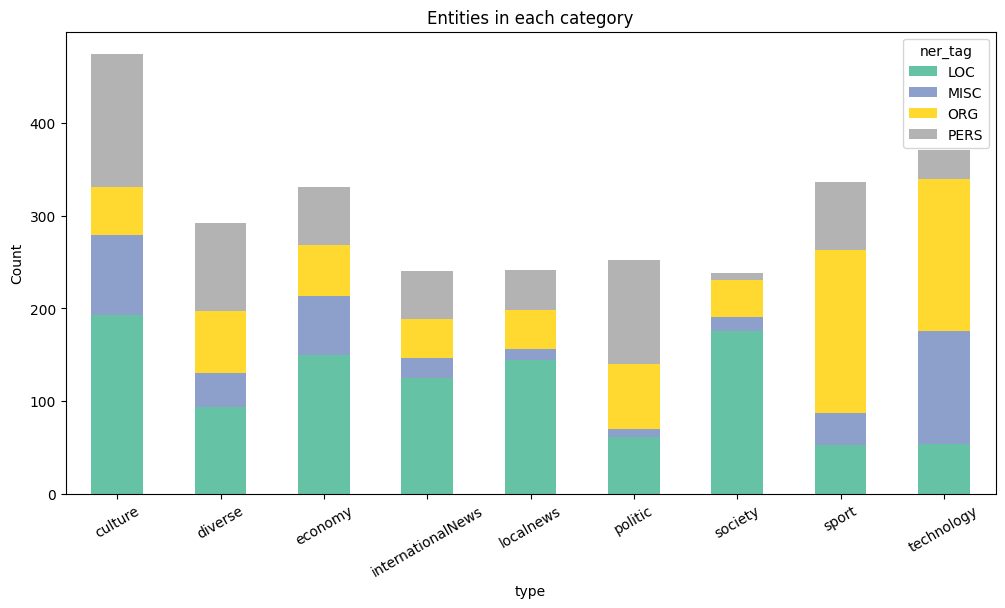

In [17]:
ner_tag_counts = ner_df["ner_tag"].value_counts()
print(ner_tag_counts)

pd.crosstab(ner_df["type"], ner_df["ner_tag"]).plot.bar(stacked=True, colormap="Set2")
plt.title("Entities in each category")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.show()

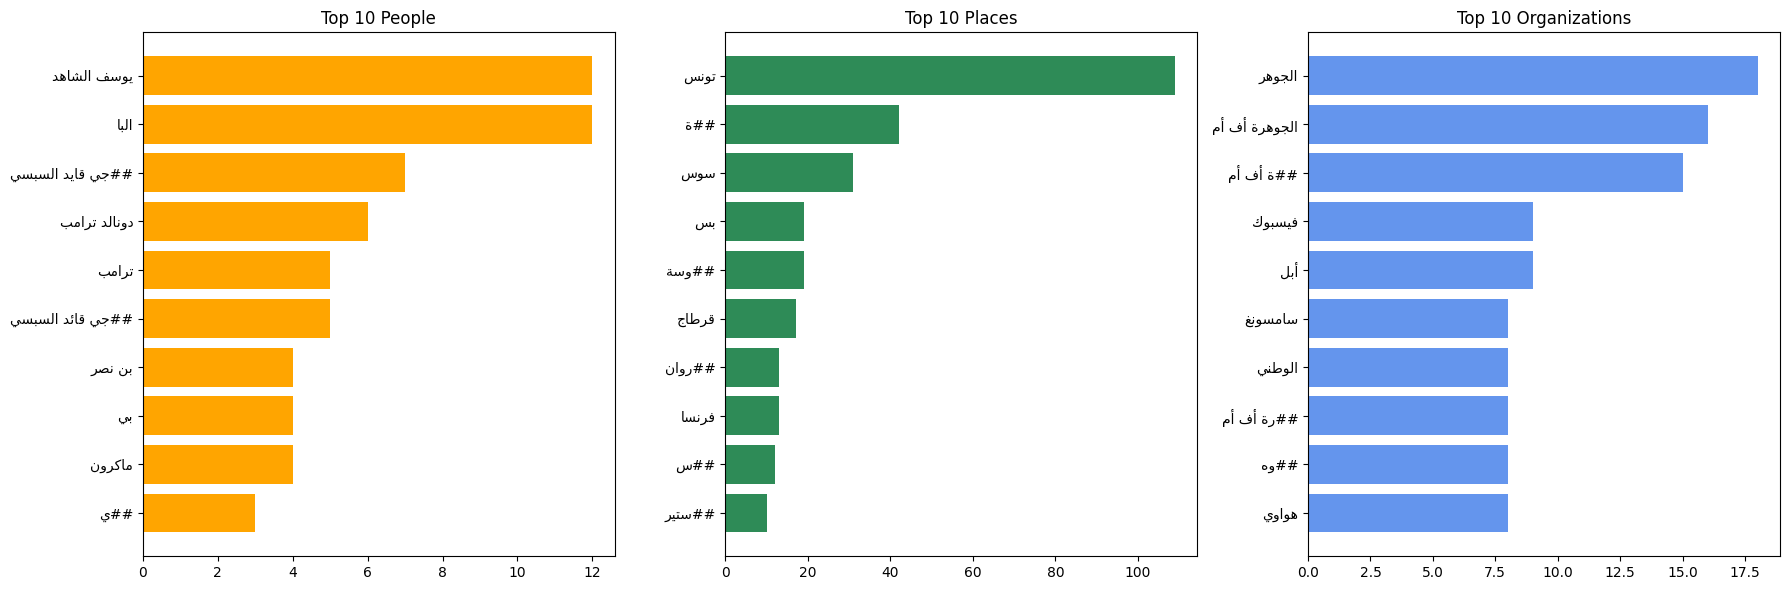

Entities that appear only once: 1180 out of 1581


In [18]:
ner_counts = ner_df.groupby(["token", "ner_tag"]).size().reset_index(name="counts").sort_values("counts", ascending=False)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for i, (tag, name, color) in enumerate([("PERS", "People", "orange"), ("LOC", "Places", "seagreen"), ("ORG", "Organizations", "cornflowerblue")]):
    s = ner_counts[ner_counts.ner_tag == tag][:10][::-1]
    ax[i].barh([ar(x) for x in s["token"]], s["counts"], color=color)
    ax[i].set_title("Top 10 " + name)
plt.tight_layout()
plt.show()

print("Entities that appear only once:", (ner_counts["counts"] == 1).sum(), "out of", len(ner_counts))

Sentiment Analysis

There are no sentiment labels in this data, so I compare 3 pretrained Arabic sentiment models on the summary of each article (the summary is short and gives the main idea).

In [19]:
sent_models = {
    "CAMeLBERT-DA": "CAMeL-Lab/bert-base-arabic-camelbert-da-sentiment",
    "CAMeLBERT-Mix": "CAMeL-Lab/bert-base-arabic-camelbert-mix-sentiment",
    "XLM-RoBERTa": "cardiffnlp/twitter-xlm-roberta-base-sentiment",
}

summaries = data["summarizer"].str.strip().tolist()
for name, model_name in sent_models.items():
    start = time.time()
    clf = pipeline("sentiment-analysis", model=model_name, device=device)
    preds = clf(summaries, batch_size=64, truncation=True, max_length=128)
    data[name] = [p["label"].lower() for p in preds]
    print(name, "done in", round(time.time() - start), "sec")
    print(data[name].value_counts(), "\n")

CAMeLBERT-DA done in 68 sec
CAMeLBERT-DA
neutral     5460
negative    2306
positive     612
Name: count, dtype: int64 



CAMeLBERT-Mix done in 74 sec
CAMeLBERT-Mix
neutral     6390
negative    1430
positive     558
Name: count, dtype: int64 



XLM-RoBERTa done in 90 sec
XLM-RoBERTa
negative    3806
neutral     2900
positive    1672
Name: count, dtype: int64 



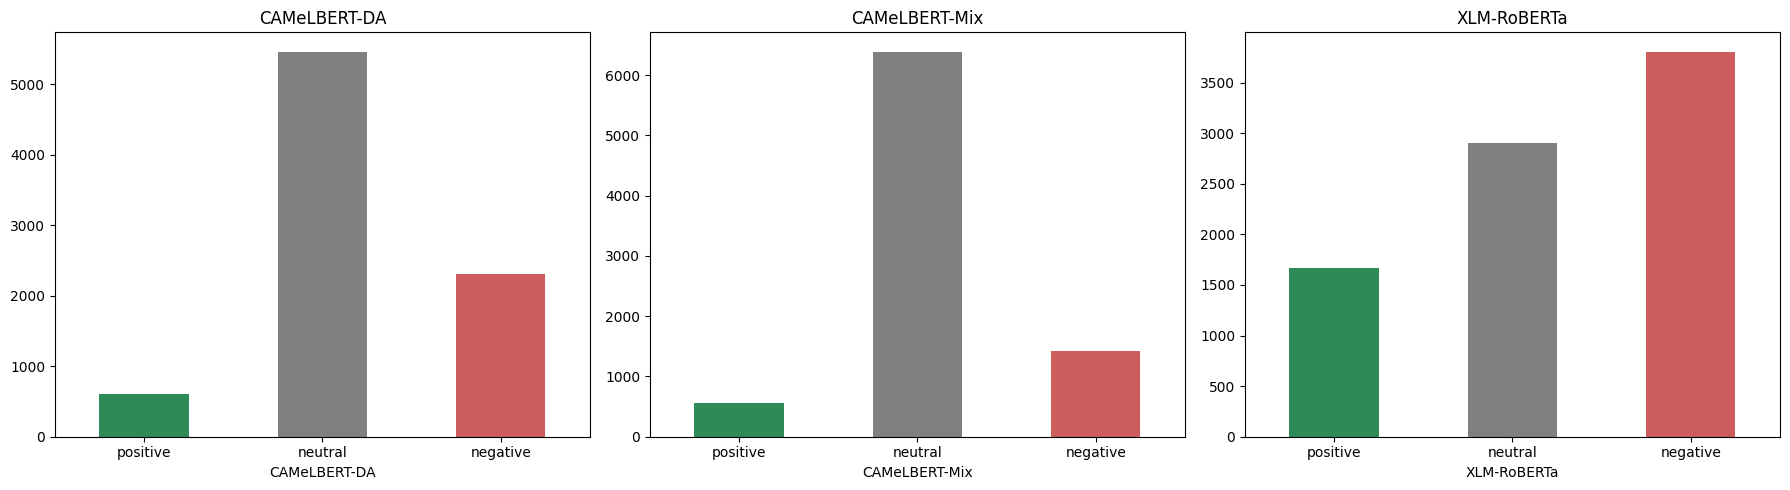

In [20]:
order = ["positive", "neutral", "negative"]
colors = ["seagreen", "gray", "indianred"]

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for i, name in enumerate(sent_models):
    data[name].value_counts().reindex(order, fill_value=0).plot.bar(ax=ax[i], color=colors)
    ax[i].set_title(name)
    ax[i].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

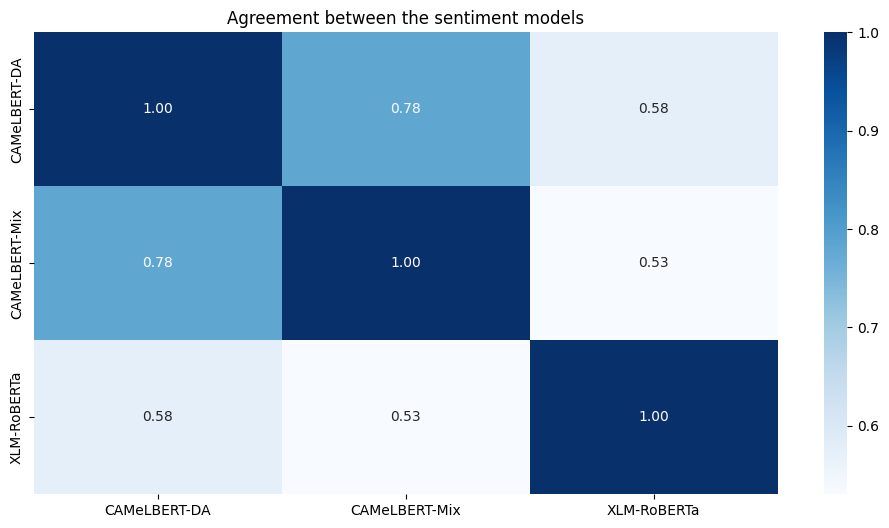

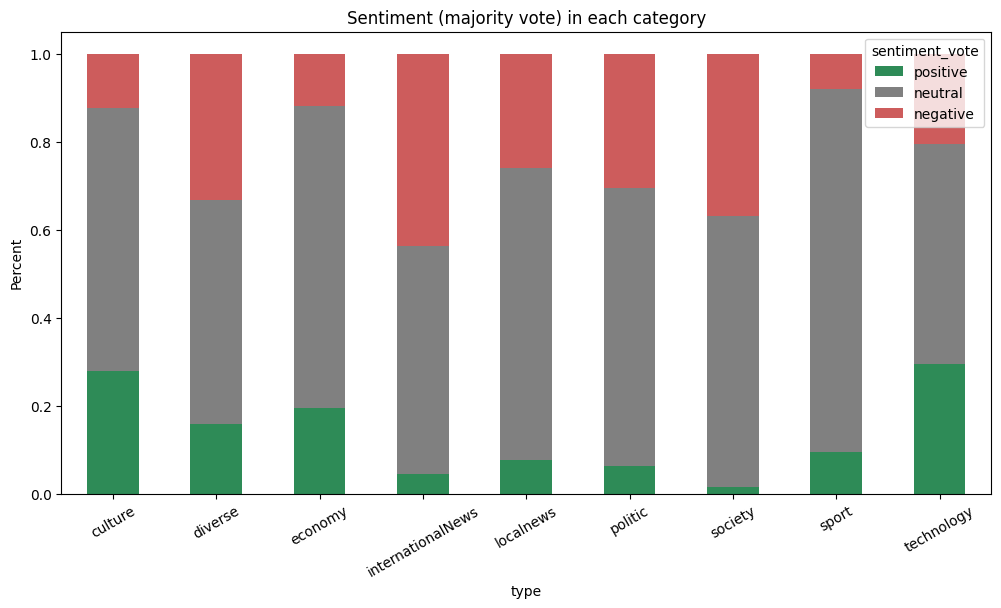

In [21]:
names = list(sent_models)
agree = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        agree.loc[a, b] = (data[a] == data[b]).mean()

sns.heatmap(agree, annot=True, fmt=".2f", cmap="Blues")
plt.title("Agreement between the sentiment models")
plt.show()

data["sentiment_vote"] = data[names].mode(axis=1)[0]
pd.crosstab(data["type"], data["sentiment_vote"], normalize="index").reindex(columns=order).plot.bar(stacked=True, color=colors)
plt.title("Sentiment (majority vote) in each category")
plt.ylabel("Percent")
plt.xticks(rotation=30)
plt.show()

Topic Modeling (3 models: LDA, LSA with TF-IDF, NMF)

I used 3000 random articles to make it faster, and compared the models with the coherence score.

In [22]:
tm_data = data.sample(3000, random_state=42).reset_index(drop=True)
texts = tm_data["tokens"].tolist()

dictionary = corpora.Dictionary(texts)
dictionary.filter_extremes(no_below=10, no_above=0.4)
doc_term = [dictionary.doc2bow(t) for t in texts]
tfidf_corpus = TfidfModel(doc_term)[doc_term]
print("Vocabulary size:", len(dictionary))

tfidf_vec = TfidfVectorizer(vocabulary=list(dictionary.token2id.keys()))
tfidf_matrix = tfidf_vec.fit_transform(tm_data["text_clean"])
nmf_words = tfidf_vec.get_feature_names_out()

Vocabulary size: 4110


In [23]:
def topics_lda(k):
    model = LdaModel(doc_term, num_topics=k, id2word=dictionary, passes=5, random_state=42)
    return [[w for w, _ in model.show_topic(i, 10)] for i in range(k)]

def topics_lsa(k):
    model = LsiModel(tfidf_corpus, num_topics=k, id2word=dictionary, random_seed=42)
    return [[w for w, _ in model.show_topic(i, 10)] for i in range(k)]

def topics_nmf(k):
    model = NMF(n_components=k, random_state=42, max_iter=400)
    model.fit(tfidf_matrix)
    return [[nmf_words[j] for j in comp.argsort()[::-1][:10]] for comp in model.components_]

def coherence(topics):
    return CoherenceModel(topics=topics, texts=texts, dictionary=dictionary, coherence="c_v").get_coherence()

results = []
all_topics = {}
for k in [5, 9, 13]:
    for name, func in [("LDA", topics_lda), ("LSA", topics_lsa), ("NMF", topics_nmf)]:
        topics = func(k)
        all_topics[(name, k)] = topics
        results.append([name, k, coherence(topics)])

coh = pd.DataFrame(results, columns=["model", "topics", "coherence"])
coh.pivot(index="topics", columns="model", values="coherence")

model,LDA,LSA,NMF
topics,,,
5,0.457948,0.645443,0.770346
9,0.623444,0.505261,0.757145
13,0.557982,0.457273,0.759504


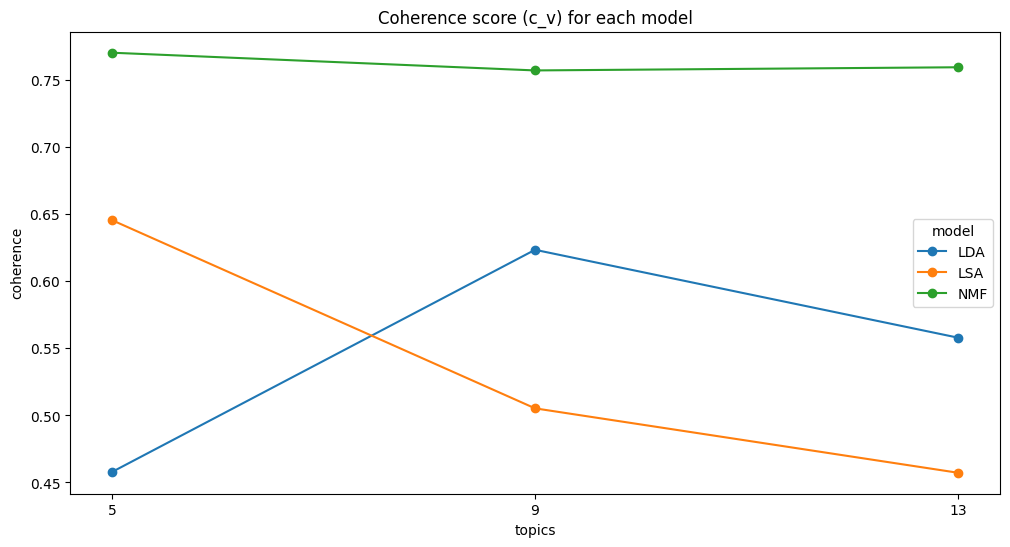

In [24]:
coh.pivot(index="topics", columns="model", values="coherence").plot(marker="o")
plt.title("Coherence score (c_v) for each model")
plt.ylabel("coherence")
plt.xticks([5, 9, 13])
plt.show()

In [25]:
best = coh.sort_values("coherence", ascending=False).iloc[0]
print("Best topic model:", best["model"], "with", best["topics"], "topics, coherence =", round(best["coherence"], 3))
print()
for i, words in enumerate(all_topics[(best["model"], best["topics"])]):
    print("Topic", i + 1, ":", " - ".join(words))

Best topic model: NMF with 5 topics, coherence = 0.77

Topic 1 : تونس - الحكومه - رئيس - العام - واضاف - وزير - الشعب - تصريح - التونسي - التونسيه
Topic 2 : الجوهره - بالجهه - اكده - مصدر - وفق - ولايه - مراسل - امني - المستشفي - العمر
Topic 3 : درجه - كلم - بالشمال - الاضطراب - ببقيه - السواحل - الجهات - وتكون - الحراره - القطاع
Topic 4 : النادي - النجم - الرياضي - لكره - الافريقي - الساحلي - القدم - الساعه - الجوله - الدور
Topic 5 : الوطني - تمكنت - للحرس - الابحاث - القبض - النيابه - العموميه - الداخليه - بلاغ - الحرس


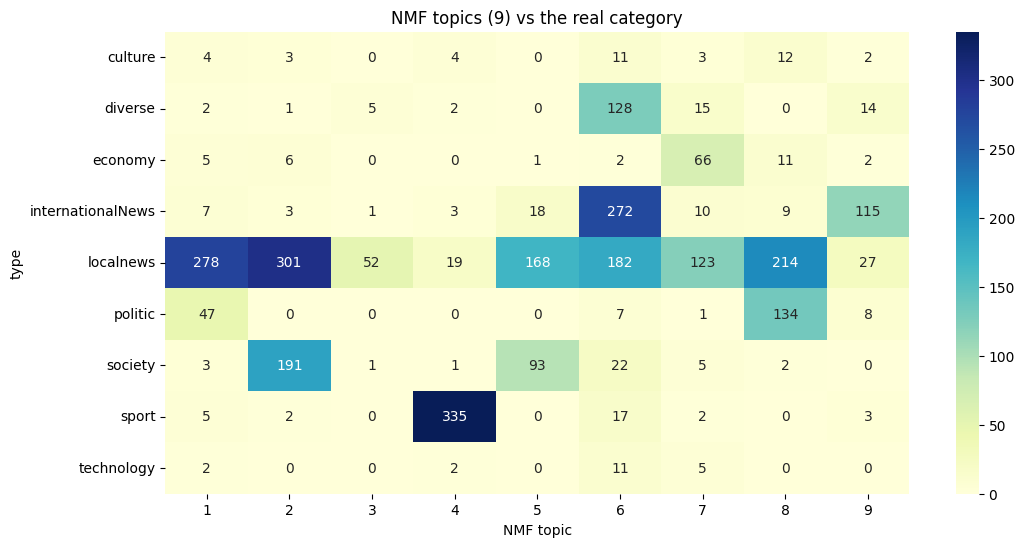

In [26]:
nmf9 = NMF(n_components=9, random_state=42, max_iter=400)
W = nmf9.fit_transform(tfidf_matrix)
tm_data["nmf_topic"] = W.argmax(axis=1) + 1

sns.heatmap(pd.crosstab(tm_data["type"], tm_data["nmf_topic"]), annot=True, fmt="d", cmap="YlGnBu")
plt.title("NMF topics (9) vs the real category")
plt.xlabel("NMF topic")
plt.show()

Machine Learning models with TF-IDF (predict the category)

In [27]:
X_train, X_test, y_train, y_test = train_test_split(data["text_clean"], data["type"], test_size=0.2, random_state=42, stratify=data["type"])
print(len(X_train), len(X_test))

ml_models = {
    "Logistic Regression": make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=2000)),
    "Naive Bayes": make_pipeline(TfidfVectorizer(), MultinomialNB()),
    "SVM (SGD)": make_pipeline(TfidfVectorizer(), SGDClassifier(random_state=1)),
    "Logistic Regression (tuned)": make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), LogisticRegression(C=10, class_weight="balanced", max_iter=3000)),
    "Naive Bayes (tuned)": make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), MultinomialNB(alpha=0.05)),
    "Linear SVM (tuned)": make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), LinearSVC(C=0.5, class_weight="balanced")),
}

rows = []
for name, model in ml_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    rows.append([name, accuracy_score(y_test, y_pred), f1_score(y_test, y_pred, average="macro")])

ml_results = pd.DataFrame(rows, columns=["model", "accuracy", "macro_f1"]).sort_values("accuracy", ascending=False).reset_index(drop=True)
ml_results

6702 1676


,model,accuracy,macro_f1
0,Linear SVM (tuned),0.807876,0.753239
1,Logistic Regression (tuned),0.804296,0.739567
2,SVM (SGD),0.797136,0.719280
3,Naive Bayes (tuned),0.790573,0.659495
4,Logistic Regression,0.761337,0.529621
5,Naive Bayes,0.576969,0.213420


Linear SVM (tuned)
                   precision    recall  f1-score   support

          culture      0.778     0.737     0.757        19
          diverse      0.705     0.632     0.667        87
          economy      0.660     0.596     0.626        52
internationalNews      0.800     0.919     0.855       235
        localnews      0.858     0.785     0.820       759
          politic      0.756     0.839     0.795       118
          society      0.616     0.734     0.670       184
            sport      0.971     0.966     0.968       206
       technology      0.692     0.562     0.621        16

         accuracy                          0.808      1676
        macro avg      0.759     0.752     0.753      1676
     weighted avg      0.813     0.808     0.808      1676



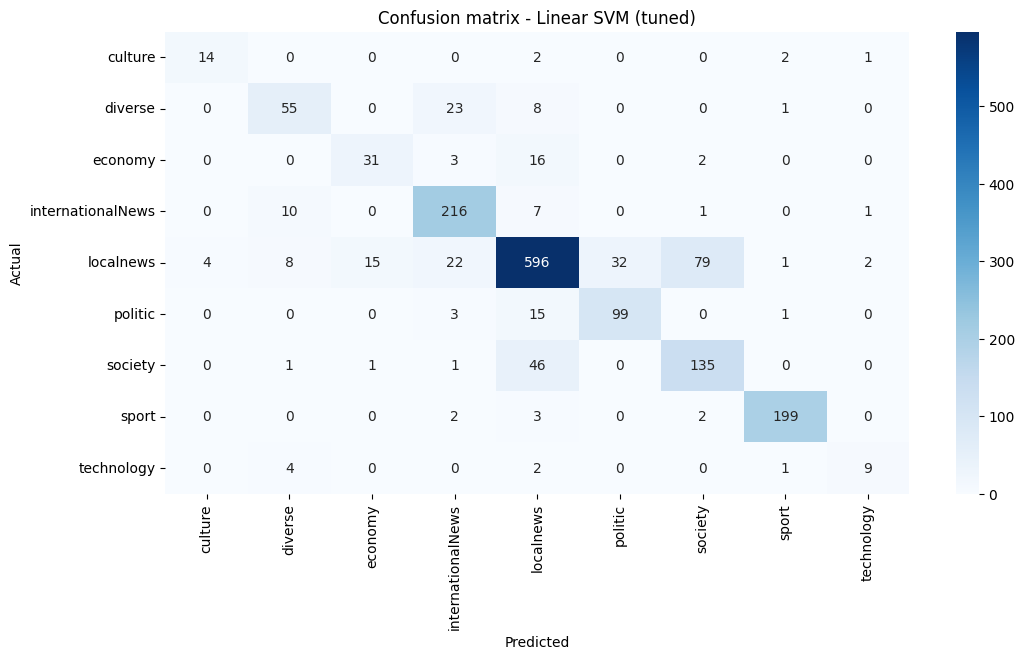

In [28]:
best_ml = ml_results.loc[0, "model"]
y_pred = ml_models[best_ml].predict(X_test)
print(best_ml)
print(classification_report(y_test, y_pred, digits=3))

labels = sorted(data["type"].unique())
sns.heatmap(confusion_matrix(y_test, y_pred, labels=labels), annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Confusion matrix - " + best_ml)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Transformers: fine tuning AraBERT to predict the category

Same train / test split as the ML models.

In [29]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
model_name = "aubmindlab/bert-base-arabertv02"
tokenizer = AutoTokenizer.from_pretrained(model_name)

label2id = {l: i for i, l in enumerate(labels)}
train_texts = data.loc[X_train.index, "text"].tolist()
test_texts = data.loc[X_test.index, "text"].tolist()

def make_loader(texts, y, shuffle):
    enc = tokenizer(texts, truncation=True, padding="max_length", max_length=256, return_tensors="pt")
    ids = torch.tensor([label2id[l] for l in y])
    return DataLoader(TensorDataset(enc["input_ids"], enc["attention_mask"], ids), batch_size=16, shuffle=shuffle)

train_loader = make_loader(train_texts, y_train, True)
test_loader = make_loader(test_texts, y_test, False)

bert = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=len(labels)).to("cuda")
optimizer = torch.optim.AdamW(bert.parameters(), lr=3e-5)
scaler = torch.amp.GradScaler()

[transformers] BertForSequenceClassification LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [30]:
def predict(loader):
    bert.eval()
    preds = []
    with torch.no_grad():
        for ids, mask, _ in loader:
            with torch.autocast("cuda", dtype=torch.float16):
                logits = bert(input_ids=ids.cuda(), attention_mask=mask.cuda()).logits
            preds += logits.argmax(1).cpu().tolist()
    return [labels[p] for p in preds]

for epoch in range(3):
    bert.train()
    total = 0
    start = time.time()
    for ids, mask, y in train_loader:
        optimizer.zero_grad()
        with torch.autocast("cuda", dtype=torch.float16):
            loss = bert(input_ids=ids.cuda(), attention_mask=mask.cuda(), labels=y.cuda()).loss
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total += loss.item()
    y_pred_bert = predict(test_loader)
    print(f"Epoch {epoch + 1} - loss {total / len(train_loader):.4f} - test accuracy {accuracy_score(y_test, y_pred_bert):.4f} - {time.time() - start:.0f} sec")

Epoch 1 - loss 0.6631 - test accuracy 0.7971 - 103 sec
Epoch 2 - loss 0.3920 - test accuracy 0.8258 - 103 sec
Epoch 3 - loss 0.2905 - test accuracy 0.8234 - 103 sec


In [31]:
bert_acc = accuracy_score(y_test, y_pred_bert)
bert_f1 = f1_score(y_test, y_pred_bert, average="macro")
print(classification_report(y_test, y_pred_bert, digits=3))

                   precision    recall  f1-score   support

          culture      0.833     0.789     0.811        19
          diverse      0.841     0.667     0.744        87
          economy      0.633     0.731     0.679        52
internationalNews      0.810     0.928     0.865       235
        localnews      0.874     0.802     0.837       759
          politic      0.707     0.797     0.749       118
          society      0.641     0.728     0.682       184
            sport      0.980     0.976     0.978       206
       technology      0.812     0.812     0.812        16

         accuracy                          0.823      1676
        macro avg      0.792     0.803     0.795      1676
     weighted avg      0.830     0.823     0.825      1676



Comparison of all results

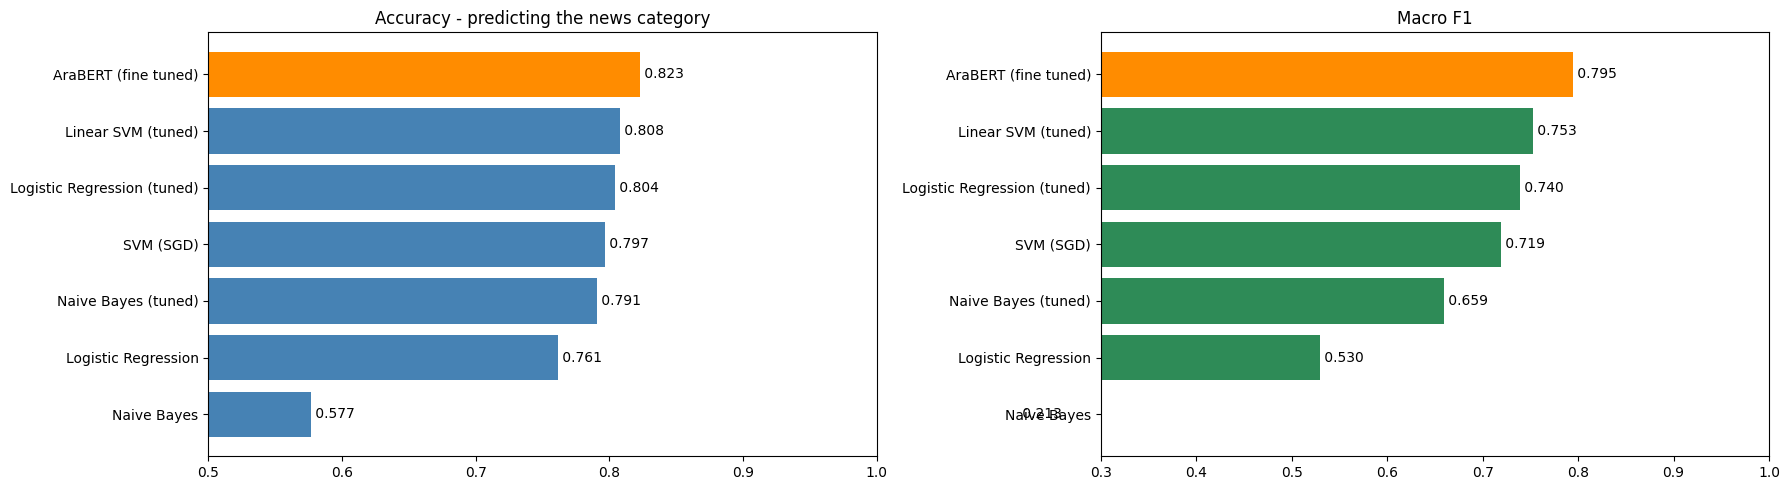

In [32]:
all_results = pd.concat([ml_results, pd.DataFrame([["AraBERT (fine tuned)", bert_acc, bert_f1]], columns=ml_results.columns)])
all_results = all_results.sort_values("accuracy").reset_index(drop=True)

fig, ax = plt.subplots(1, 2, figsize=(18, 5))
ax[0].barh(all_results["model"], all_results["accuracy"], color=["darkorange" if "BERT" in m else "steelblue" for m in all_results["model"]])
ax[0].set_xlim(0.5, 1)
ax[0].set_title("Accuracy - predicting the news category")
for i, v in enumerate(all_results["accuracy"]):
    ax[0].text(v, i, f" {v:.3f}", va="center")
ax[1].barh(all_results["model"], all_results["macro_f1"], color=["darkorange" if "BERT" in m else "seagreen" for m in all_results["model"]])
ax[1].set_xlim(0.3, 1)
ax[1].set_title("Macro F1")
for i, v in enumerate(all_results["macro_f1"]):
    ax[1].text(v, i, f" {v:.3f}", va="center")
plt.tight_layout()
plt.show()

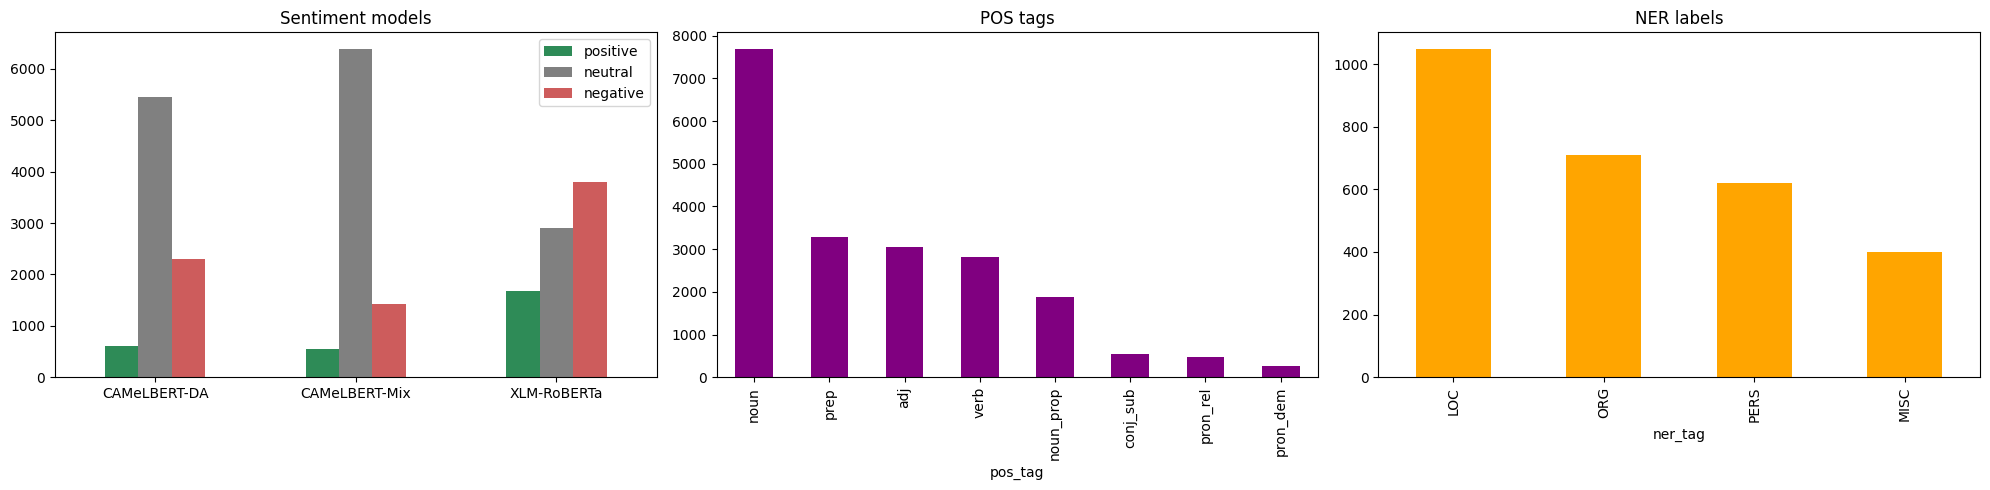

In [33]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))

pd.DataFrame({n: data[n].value_counts().reindex(order, fill_value=0) for n in names}).T.plot.bar(ax=ax[0], color=colors)
ax[0].set_title("Sentiment models")
ax[0].tick_params(axis="x", rotation=0)

pos_tag_counts.head(8).plot.bar(ax=ax[1], color="purple")
ax[1].set_title("POS tags")

ner_tag_counts.plot.bar(ax=ax[2], color="orange")
ax[2].set_title("NER labels")
plt.tight_layout()
plt.show()

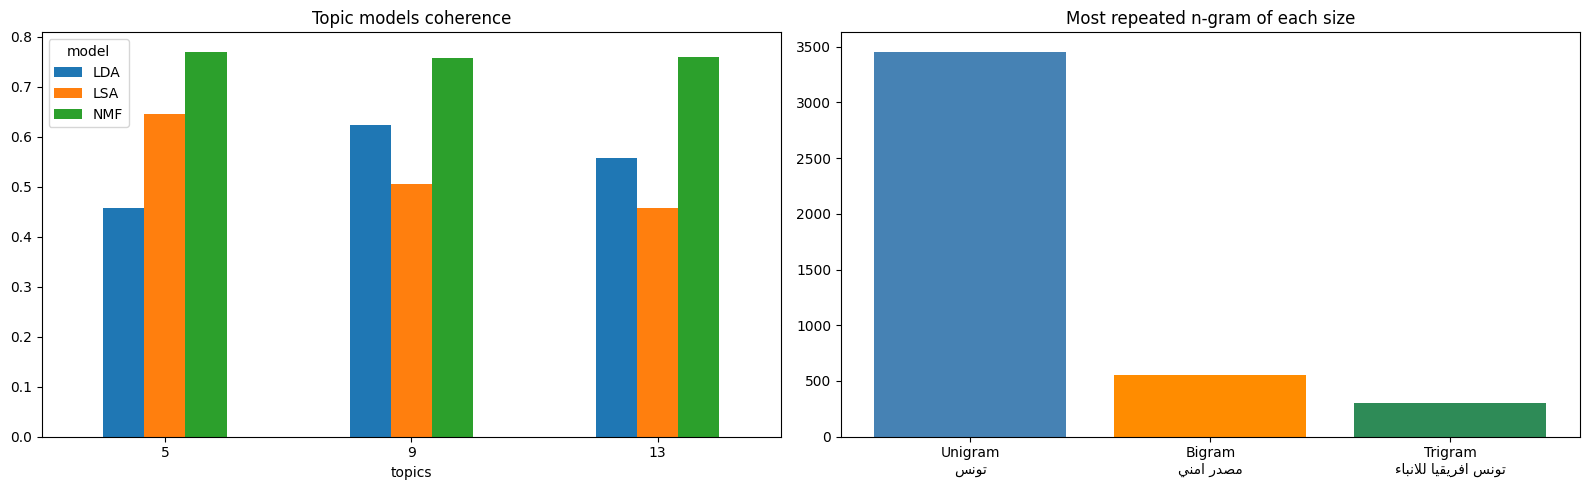

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

coh.pivot(index="topics", columns="model", values="coherence").plot.bar(ax=ax[0])
ax[0].set_title("Topic models coherence")
ax[0].tick_params(axis="x", rotation=0)

top_ngrams = pd.DataFrame({
    "n-gram": ["Unigram", "Bigram", "Trigram"],
    "top": [ar(unigrams.index[0]), ar(bigrams.index[0]), ar(trigrams.index[0])],
    "count": [unigrams.iloc[0], bigrams.iloc[0], trigrams.iloc[0]],
})
ax[1].bar(top_ngrams["n-gram"] + "\n" + top_ngrams["top"], top_ngrams["count"], color=["steelblue", "darkorange", "seagreen"])
ax[1].set_title("Most repeated n-gram of each size")
plt.tight_layout()
plt.show()

In [35]:
summary = pd.DataFrame([
    ["Category classification", "best ML: " + ml_results.loc[0, "model"], round(ml_results.loc[0, "accuracy"], 3)],
    ["Category classification", "AraBERT (fine tuned)", round(bert_acc, 3)],
    ["Topic modeling", "best: " + best["model"] + " (" + str(best["topics"]) + " topics)", round(best["coherence"], 3)],
    ["Sentiment", "most common label (vote)", data["sentiment_vote"].value_counts().index[0]],
    ["POS", "most common tag", pos_tag_counts.index[0]],
    ["NER", "most common entity type", ner_tag_counts.index[0]],
    ["N-grams", "top unigram", unigrams.index[0]],
    ["N-grams", "top bigram", bigrams.index[0]],
], columns=["task", "result", "value"])
summary

,task,result,value
0,Category classification,best ML: Linear SVM (tuned),0.808
1,Category classification,AraBERT (fine tuned),0.823
2,Topic modeling,best: NMF (5 topics),0.77
3,Sentiment,most common label (vote),neutral
4,POS,most common tag,noun
5,NER,most common entity type,LOC
6,N-grams,top unigram,تونس
7,N-grams,top bigram,مصدر امني


Conclusion

- Category classification: AraBERT fine tuned got the best accuracy (82.3%), the best ML model with TF-IDF was Linear SVM tuned (80.8%), sport is the easiest class and society / economy are the hardest.
- Topic modeling: NMF gave the best coherence (0.77) and its topics match real categories (sport, weather, security, government).
- Sentiment: the two CAMeLBERT models say most news is neutral, XLM-RoBERTa gives more negative, news text is mostly neutral so the CAMeLBERT results make more sense.
- POS: nouns are the most common tag. NER: locations are the most common entities (Tunisia is the top word and part of the top trigram).
